In [30]:
import pandas as pd

iv = pd.read_csv("../outputs/final_iv_summary.csv")

iv = iv.sort_values("iv", ascending=False)

iv

,feature,iv,n_bins,strength
0,int_rate,4.435380e-01,8,Strong
1,fico_range_low,1.155140e-01,7,Medium
2,fico_range_high,1.155140e-01,7,Medium
3,acc_open_past_24mths,7.759093e-02,8,Weak
4,dti,6.829964e-02,7,Weak
...,...,...,...,...
72,tax_liens,6.244732e-06,2,Unpredictive
73,acc_now_delinq,1.169176e-06,2,Unpredictive
74,delinq_amnt,1.169176e-06,2,Unpredictive
75,collections_12_mths_ex_med,8.320255e-07,2,Unpredictive


In [31]:
def iv_strength(iv):
    if iv < 0.02:
        return "Unpredictive"
    elif iv < 0.10:
        return "Weak"
    elif iv < 0.30:
        return "Medium"
    elif iv < 0.50:
        return "Strong"
    else:
        return "Suspicious"

iv["strength"] = iv["iv"].apply(iv_strength)

iv

,feature,iv,n_bins,strength
0,int_rate,4.435380e-01,8,Strong
1,fico_range_low,1.155140e-01,7,Medium
2,fico_range_high,1.155140e-01,7,Medium
3,acc_open_past_24mths,7.759093e-02,8,Weak
4,dti,6.829964e-02,7,Weak
...,...,...,...,...
72,tax_liens,6.244732e-06,2,Unpredictive
73,acc_now_delinq,1.169176e-06,2,Unpredictive
74,delinq_amnt,1.169176e-06,2,Unpredictive
75,collections_12_mths_ex_med,8.320255e-07,2,Unpredictive


In [32]:
import pandas as pd
import numpy as np

train = pd.read_csv(
    "../outputs/train.csv",
    low_memory=False
)

target = "default_flag"

In [33]:
categorical_features = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

categorical_features

['term',
 'grade',
 'sub_grade',
 'emp_title',
 'emp_length',
 'home_ownership',
 'verification_status',
 'issue_d',
 'pymnt_plan',
 'purpose',
 'title',
 'zip_code',
 'addr_state',
 'earliest_cr_line',
 'initial_list_status',
 'application_type',
 'verification_status_joint',
 'disbursement_method']

In [34]:
def categorical_iv(df, feature, target="default_flag"):

    temp = pd.DataFrame({
        "feature": df[feature].astype("object").fillna("Missing"),
        "target": df[target]
    })

    summary = (
        temp
        .groupby("feature", observed=False)["target"]
        .agg(
            total="count",
            bad="sum"
        )
    )

    summary["good"] = (
        summary["total"] - summary["bad"]
    )

    total_good = summary["good"].sum()
    total_bad = summary["bad"].sum()

    n_bins = len(summary)

    dist_good = (
        (summary["good"] + 0.5)
        / (total_good + 0.5 * n_bins)
    )

    dist_bad = (
        (summary["bad"] + 0.5)
        / (total_bad + 0.5 * n_bins)
    )

    summary["woe"] = np.log(
        dist_good / dist_bad
    )

    summary["iv"] = (
        (dist_good - dist_bad)
        * summary["woe"]
    )

    return summary

In [35]:
categorical_iv_results = []

for feature in categorical_features:

    table = categorical_iv(
        train,
        feature,
        target
    )

    categorical_iv_results.append({
        "feature": feature,
        "iv": table["iv"].sum(),
        "n_categories": len(table)
    })

categorical_iv_summary = (
    pd.DataFrame(categorical_iv_results)
    .sort_values("iv", ascending=False)
    .reset_index(drop=True)
)

categorical_iv_summary

,feature,iv,n_categories
0,emp_title,0.701519,45690
1,sub_grade,0.498468,35
2,grade,0.463412,7
3,title,0.217039,7760
4,term,0.195995,2
5,zip_code,0.082754,879
6,earliest_cr_line,0.059046,625
7,verification_status,0.058606,3
8,issue_d,0.042958,115
9,home_ownership,0.029441,6


In [36]:
drop_features = [
    "purpose",
    "addr_state",
    "emp_length",
    "disbursement_method",
    "application_type",
    "verification_status_joint",
    "initial_list_status",
    "pymnt_plan",
    "emp_title",
    "sub_grade",
    "issue_d",
    "earliest_cr_line",
    "title",
    "zip_code"
]

train = train.drop(columns=drop_features)

print("Dropped:")
for col in drop_features:
    print(col)

Dropped:
purpose
addr_state
emp_length
disbursement_method
application_type
verification_status_joint
initial_list_status
pymnt_plan
emp_title
sub_grade
issue_d
earliest_cr_line
title
zip_code


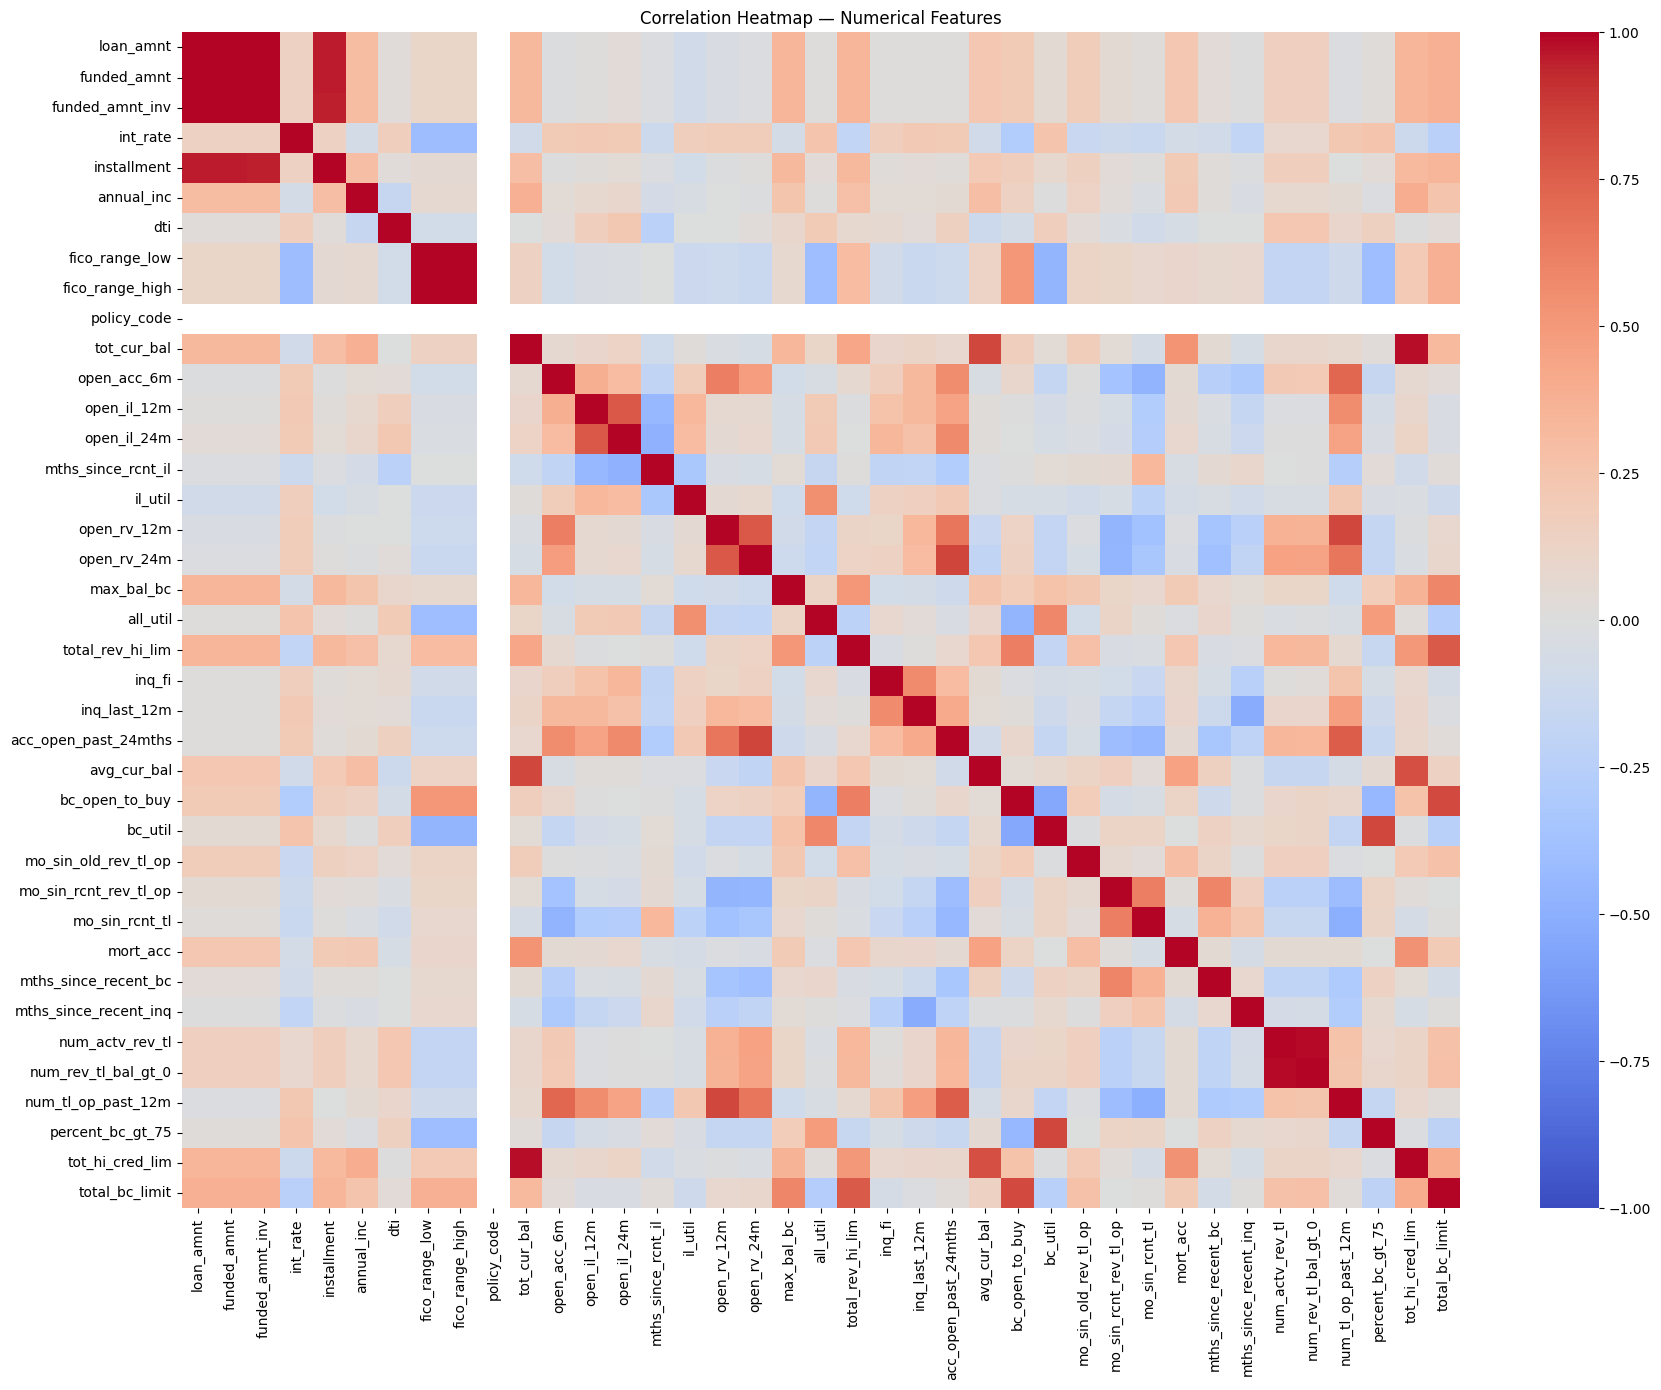

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv(
    "../outputs/train_selected.csv",
    low_memory=False
)

# Numerical features only
numerical_features = train.select_dtypes(
    include=["number"]
).columns.tolist()

numerical_features.remove("default_flag")

# Correlation matrix
corr = train[numerical_features].corr()

# Heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title("Correlation Heatmap — Numerical Features")
plt.tight_layout()

plt.show()

In [44]:
threshold = 0.70

corr_pairs = (
    corr.where(
        np.triu(
            np.ones(corr.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

corr_pairs = (
    corr_pairs[
        corr_pairs["correlation"].abs() >= threshold
    ]
    .sort_values(
        "correlation",
        key=lambda x: x.abs(),
        ascending=False
    )
)

corr_pairs

,feature_1,feature_2,correlation
238,fico_range_low,fico_range_high,1.000000
0,loan_amnt,funded_amnt,0.999517
37,funded_amnt,funded_amnt_inv,0.998417
1,loan_amnt,funded_amnt_inv,0.997819
688,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.984546
323,tot_cur_bal,tot_hi_cred_lim,0.984217
39,funded_amnt,installment,0.954121
3,loan_amnt,installment,0.953418
74,funded_amnt_inv,installment,0.952418
477,open_rv_24m,acc_open_past_24mths,0.846482


In [46]:
iv = pd.read_csv(
    "../outputs/final_iv_summary.csv"
)

iv_lookup = iv.set_index("feature")["iv"]

corr_pairs["iv_1"] = (
    corr_pairs["feature_1"]
    .map(iv_lookup)
)

corr_pairs["iv_2"] = (
    corr_pairs["feature_2"]
    .map(iv_lookup)
)

corr_pairs[
    [
        "feature_1",
        "feature_2",
        "correlation",
        "iv_1",
        "iv_2"
    ]
]

,feature_1,feature_2,correlation,iv_1,iv_2
238,fico_range_low,fico_range_high,1.000000,0.115514,0.115514
0,loan_amnt,funded_amnt,0.999517,0.034123,0.034219
37,funded_amnt,funded_amnt_inv,0.998417,0.034219,0.033395
1,loan_amnt,funded_amnt_inv,0.997819,0.034123,0.033395
688,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.984546,0.031527,0.031298
323,tot_cur_bal,tot_hi_cred_lim,0.984217,0.035179,0.044092
39,funded_amnt,installment,0.954121,0.034219,0.028501
3,loan_amnt,installment,0.953418,0.034123,0.028501
74,funded_amnt_inv,installment,0.952418,0.033395,0.028501
477,open_rv_24m,acc_open_past_24mths,0.846482,0.033739,0.077591


In [ ]:
# correlation_drop_features = [
#     "fico_range_high",
#     "funded_amnt",
#     "funded_amnt_inv",
#     "installment",
#     "num_rev_tl_bal_gt_0",
#     "tot_cur_bal"
# ]

In [48]:
import pandas as pd
import numpy as np

train_woe = pd.read_csv(
    "../outputs/train_woe.csv",
    low_memory=False
)

target = "default_flag"

features = [
    col for col in train_woe.columns
    if col != target
]

corr_woe = train_woe[features].corr()

threshold = 0.90

corr_pairs_woe = (
    corr_woe.where(
        np.triu(
            np.ones(corr_woe.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs_woe.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

corr_pairs_woe = (
    corr_pairs_woe[
        corr_pairs_woe["correlation"].abs() > threshold
    ]
    .sort_values(
        "correlation",
        key=lambda x: x.abs(),
        ascending=False
    )
    .reset_index(drop=True)
)

corr_pairs_woe

,feature_1,feature_2,correlation
0,int_rate,grade,0.945423
1,open_il_12m,open_il_24m,0.922479


In [49]:
train_woe = pd.read_csv(
    "../outputs/train_woe.csv",
    low_memory=False
)

features = [
    col for col in train_woe.columns
    if col != "default_flag"
]

corr_woe = train_woe[features].corr()

corr_pairs_woe = (
    corr_woe.where(
        np.triu(
            np.ones(corr_woe.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs_woe.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

corr_pairs_woe = (
    corr_pairs_woe[
        corr_pairs_woe["correlation"].abs() > 0.90
    ]
    .sort_values(
        "correlation",
        key=lambda x: x.abs(),
        ascending=False
    )
    .reset_index(drop=True)
)

corr_pairs_woe

,feature_1,feature_2,correlation
0,int_rate,sub_grade,0.959178


In [52]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

train_woe = pd.read_csv(
    "../outputs/train_woe.csv",
    low_memory=False
)

X = train_woe.drop(
    columns=["default_flag"]
)

vif = pd.DataFrame({
    "feature": X.columns,
    "VIF": [
        variance_inflation_factor(
            X.values,
            i
        )
        for i in range(X.shape[1])
    ]
})

vif = vif.sort_values(
    "VIF",
    ascending=False
).reset_index(drop=True)

vif

,feature,VIF
0,open_rv_12m,7.865919
1,open_acc_6m,6.672788
2,open_il_12m,6.572379
3,tot_hi_cred_lim,6.180063
4,inq_fi,5.800298
5,bc_open_to_buy,5.446248
6,total_bc_limit,5.435043
7,mths_since_rcnt_il,5.377671
8,inq_last_12m,5.349136
9,avg_cur_bal,5.225209
